In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

In [3]:
print("train shape:", train.shape)
print("test shape:", test.shape)

train shape: (76518, 38)
test shape: (51012, 37)


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 76518 entries, 0 to 76517
Data columns (total 38 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   id                                              76518 non-null  int64  
 1   Marital status                                  76518 non-null  int64  
 2   Application mode                                76518 non-null  int64  
 3   Application order                               76518 non-null  int64  
 4   Course                                          76518 non-null  int64  
 5   Daytime/evening attendance                      76518 non-null  int64  
 6   Previous qualification                          76518 non-null  int64  
 7   Previous qualification (grade)                  76518 non-null  float64
 8   Nacionality                                     76518 non-null  int64  
 9   Mother's qualification                          76

In [5]:
print(train["Target"].value_counts())
print()
print(train["Target"].value_counts(normalize=True).round(3))

Target
Graduate    36282
Dropout     25296
Enrolled    14940
Name: count, dtype: int64

Target
Graduate    0.474
Dropout     0.331
Enrolled    0.195
Name: proportion, dtype: float64


In [6]:
df = train[train["Target"] != "Enrolled"].reset_index(drop=True)

In [7]:
print("کلاس‌های باقی‌مانده:", df["Target"].unique())
print("shape:", df.shape)

کلاس‌های باقی‌مانده: <StringArray>
['Graduate', 'Dropout']
Length: 2, dtype: str
shape: (61578, 38)


In [8]:
print(df["Target"].value_counts())
print()
print(df["Target"].value_counts(normalize=True).round(3))

Target
Graduate    36282
Dropout     25296
Name: count, dtype: int64

Target
Graduate    0.589
Dropout     0.411
Name: proportion, dtype: float64


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [10]:
X = df.drop(columns=["id", "Target"])
y = (df["Target"] == "Graduate").astype(int)

In [11]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_val.shape)

(49262, 36) (12316, 36)


In [12]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

In [13]:
from sklearn.neighbors import KNeighborsClassifier

In [14]:
knn5 = KNeighborsClassifier(n_neighbors=5)
knn5.fit(X_train_s, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [15]:
pred5 = knn5.predict(X_val_s)
print(pred5[:10])

[1 0 1 1 1 0 1 1 1 1]


In [16]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

In [17]:
print("Accuracy :", accuracy_score(y_val, pred5))
print("Precision:", precision_score(y_val, pred5))
print("Recall   :", recall_score(y_val, pred5))
print("F1-Score :", f1_score(y_val, pred5))

Accuracy : 0.9195355634946412
Precision: 0.9053631866701379
Recall   : 0.9634298379276908
F1-Score : 0.9334943963492383


[[4370  727]
 [ 264 6955]]


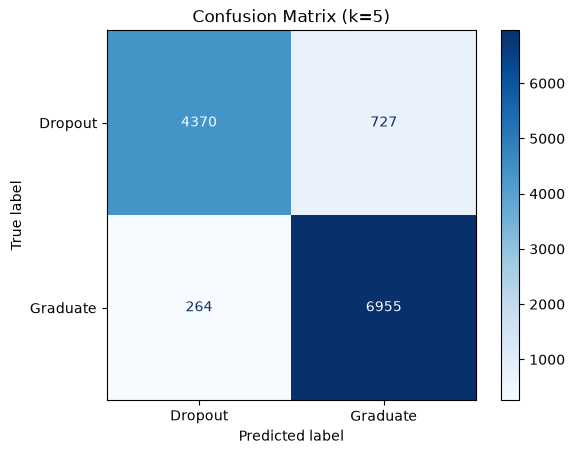

In [18]:
cm = confusion_matrix(y_val, pred5)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["Dropout", "Graduate"]).plot(cmap="Blues")
plt.title("Confusion Matrix (k=5)")
plt.show()

In [19]:
ks = [3, 5, 7, 15, 25, 50]
rows = []

for k in ks:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_s, y_train)
    pred = model.predict(X_val_s)
    rows.append({
        "k": k,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1-Score": f1_score(y_val, pred),
    })

results = pd.DataFrame(rows).set_index("k").round(4)
results

,Accuracy,Precision,Recall,F1-Score
k,,,,
3,0.9171,0.9063,0.9576,0.9312
5,0.9195,0.9054,0.9634,0.9335
7,0.9215,0.9054,0.9670,0.9352
15,0.9208,0.8998,0.9731,0.9350
25,0.9198,0.8973,0.9747,0.9344
50,0.9173,0.8934,0.9752,0.9325


In [20]:
best_k = results["F1-Score"].idxmax()
print("بهترین k:", best_k)

بهترین k: 7


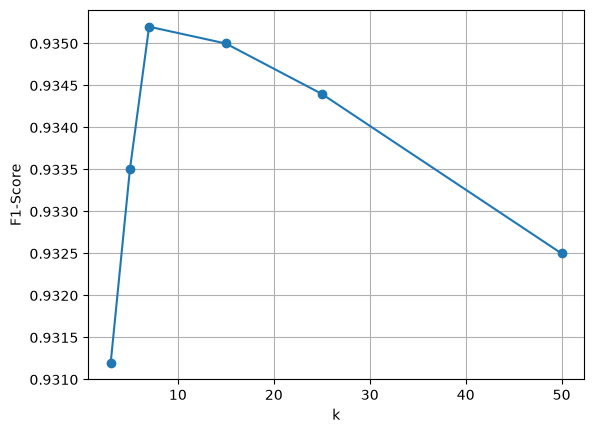

In [21]:
plt.plot(results.index, results["F1-Score"], marker="o")
plt.xlabel("k")
plt.ylabel("F1-Score")
plt.grid(True)
plt.show()

Accuracy : 0.9214842481325105
Precision: 0.9054474708171206
Recall   : 0.9670314447984485
F1-Score : 0.9352267399022037
[[4368  729]
 [ 238 6981]]


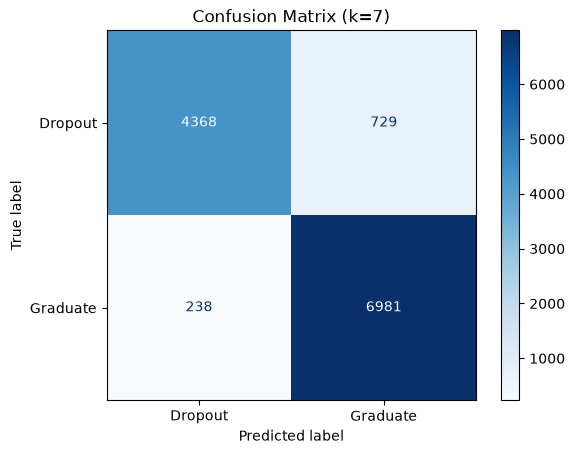

In [22]:
final = KNeighborsClassifier(n_neighbors=best_k)
final.fit(X_train_s, y_train)
pred_f = final.predict(X_val_s)

print("Accuracy :", accuracy_score(y_val, pred_f))
print("Precision:", precision_score(y_val, pred_f))
print("Recall   :", recall_score(y_val, pred_f))
print("F1-Score :", f1_score(y_val, pred_f))

cm_f = confusion_matrix(y_val, pred_f)
print(cm_f)
ConfusionMatrixDisplay(cm_f, display_labels=["Dropout", "Graduate"]).plot(cmap="Blues")
plt.title(f"Confusion Matrix (k={best_k})")
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.9;">

<h2>مشاهدات</h2>

<ol>
<li>بهترین F1-Score مربوط به <b>k=7</b> بود (F1 ≈ 0.9352، Accuracy ≈ 0.9215).</li>
<li>k=7 را انتخاب کردم چون بالاترین F1 و Accuracy را داشت و F1 تعادل بین Precision (0.9054) و Recall (0.9670) را می‌سنجد.</li>
<li>با k کوچک (3) مدل به نویز حساس است و F1 پایین‌تر بود (0.9312)؛ با افزایش k مرز تصمیم هموارتر شد و F1 تا k=7 بهتر شد.</li>
<li>با بزرگ‌تر شدن k، Recall مدام بالا رفت و Precision پایین آمد (مدل به کلاس اکثریت Graduate متمایل شد)؛ در k=50 F1 افت کرد (0.9320).</li>
<li>تفاوت F1 بین k=7 و k=15 بسیار ناچیز بود (حدود 0.0002)، پس مدل در این بازه پایدار است و رفتار آن منطقی بود.</li>
</ol>

</div>